# Lógica Difusa aplicada a Inteligencia Artificial
## Caso: prioridad de despacho de un pedido en Mercado Libre

El pedido **ML-2048** espera en una cola logística. Para asignarle una prioridad se usarán dos datos conocidos:

- **Reputación del vendedor:** $r=65$ sobre 100.
- **Urgencia operativa:** $u=7$ sobre 10.

Un sistema difuso transformará esas entradas en un puntaje continuo de prioridad $p$ entre 0 y 100.

> **Alcance del ejemplo:** el pedido, las entradas, las funciones de pertenencia y las reglas son hipotéticos y se usan con fines didácticos. No describen ni afirman reproducir el algoritmo real de Mercado Libre. Los rangos y reglas deben validarse con evidencia operativa antes de usar un sistema de priorización real.

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

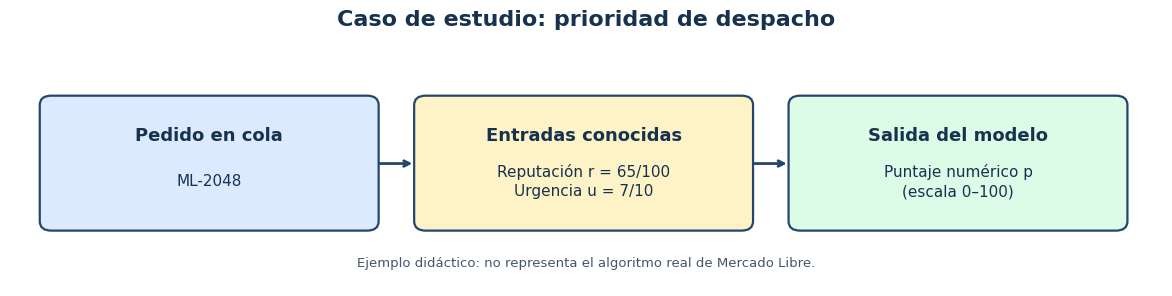

In [ ]:
# Diagrama del caso: solo usa los datos hipotéticos definidos en la introducción.
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 3.2), facecolor="white")
ax.set_facecolor("white")
ax.set_xlim(0, 12)
ax.set_ylim(0, 3.2)
ax.axis("off")

cards = [
    (0.35, "Pedido en cola", "ML-2048", "#dbeafe"),
    (4.25, "Entradas conocidas", "Reputación r = 65/100\nUrgencia u = 7/10", "#fef3c7"),
    (8.15, "Salida del modelo", "Puntaje numérico p\n(escala 0–100)", "#dcfce7"),
]
for x, title, detail, color in cards:
    box = FancyBboxPatch((x, 0.75), 3.45, 1.65,
                         boxstyle="round,pad=0.04,rounding_size=0.12",
                         linewidth=1.6, edgecolor="#24466b", facecolor=color)
    ax.add_patch(box)
    ax.text(x + 1.725, 1.93, title, ha="center", va="center",
            fontsize=13, fontweight="bold", color="#16324f")
    ax.text(x + 1.725, 1.35, detail, ha="center", va="center",
            fontsize=11, color="#16324f", linespacing=1.35)
for x1, x2 in [(3.82, 4.22), (7.72, 8.12)]:
    ax.annotate("", xy=(x2, 1.57), xytext=(x1, 1.57),
                arrowprops=dict(arrowstyle="->", lw=2, color="#24466b"))
ax.text(6, 0.3, "Ejemplo didáctico: no representa el algoritmo real de Mercado Libre.",
        ha="center", va="center", fontsize=9.5, color="#475569")
ax.set_title("Caso de estudio: prioridad de despacho", fontsize=16,
             fontweight="bold", color="#16324f", pad=8)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.05, top=0.83)
plt.show()

# 1. De un umbral rígido a una interpretación gradual

Una política clásica podría definir **reputación alta** así: $r\geq70$. Con esa frontera, 69 no pertenece y 70 sí pertenece por completo.

La lógica difusa conserva el puntaje original y calcula un **grado de pertenencia**:

$$\mu_{\text{alta}}(r)\in[0,1]$$

La letra griega $\mu$ se pronuncia **mu**. La expresión $\mu_{\text{alta}}(65)$ indica cuánto encaja el puntaje 65 en el concepto lingüístico *reputación alta*.

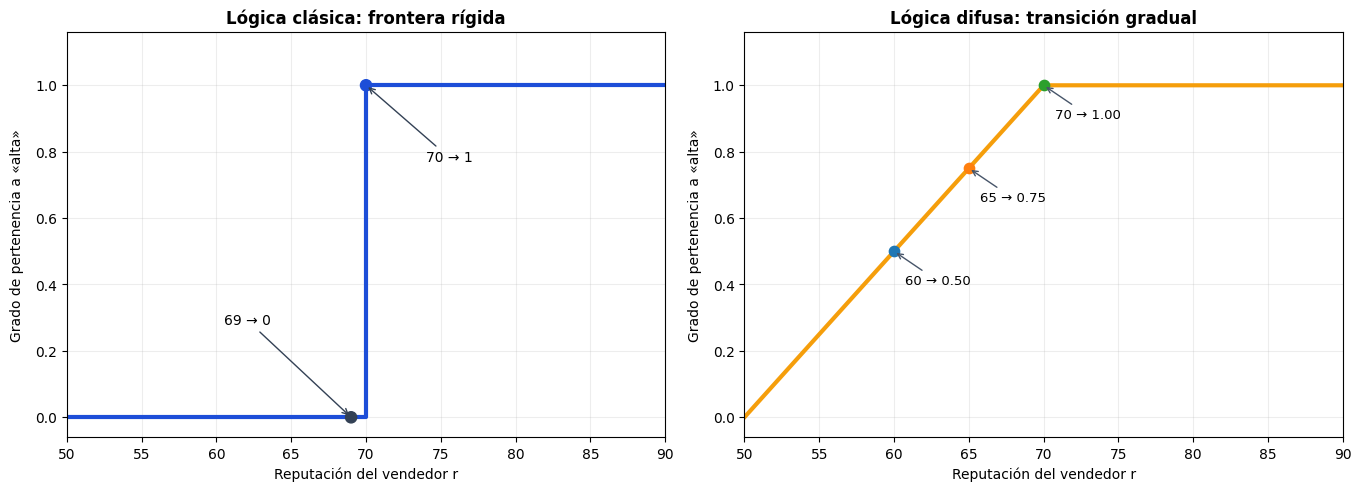

In [ ]:
# Comparación visual de un umbral rígido con una pertenencia gradual.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True, facecolor="white")
xs = np.linspace(50, 90, 401)

# Política clásica: r < 70 -> 0; r >= 70 -> 1.
axes[0].plot([50, 70, 70, 90], [0, 0, 1, 1], color="#1d4ed8", lw=3)
axes[0].scatter([69, 70], [0, 1], color=["#334155", "#1d4ed8"], s=65, zorder=3)
axes[0].annotate("69 → 0", (69, 0), xytext=(60.5, 0.28),
                 arrowprops=dict(arrowstyle="->", color="#334155"), fontsize=10)
axes[0].annotate("70 → 1", (70, 1), xytext=(74, 0.77),
                 arrowprops=dict(arrowstyle="->", color="#334155"), fontsize=10)
axes[0].set_title("Lógica clásica: frontera rígida", fontsize=12, fontweight="bold")

# Para mostrar la transición usada en el ejemplo: 50 -> 0, 70 -> 1 y luego se mantiene en 1.
fuzzy = np.clip((xs - 50) / 20, 0, 1)
axes[1].plot(xs, fuzzy, color="#f59e0b", lw=3)
for x, y, label, offset in [(60, 0.50, "60 → 0.50", (8, -24)),
                            (65, 0.75, "65 → 0.75", (8, -24)),
                            (70, 1.00, "70 → 1.00", (8, -24))]:
    axes[1].scatter([x], [y], s=55, zorder=3)
    axes[1].annotate(label, (x, y), xytext=offset, textcoords="offset points",
                     fontsize=9.5, arrowprops=dict(arrowstyle="->", color="#475569"))
axes[1].set_title("Lógica difusa: transición gradual", fontsize=12, fontweight="bold")
for ax in axes:
    ax.set_xlim(50, 90)
    ax.set_ylim(-0.06, 1.16)
    ax.set_xlabel("Reputación del vendedor r")
    ax.set_ylabel("Grado de pertenencia a «alta»", labelpad=8)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(alpha=0.22)
fig.patch.set_facecolor("white")
plt.show()

## Pertenencia difusa no es probabilidad

Para las funciones utilizadas en el caso:

$$\mu_{\text{baja}}(65)=0,\qquad \mu_{\text{media}}(65)=0.25,\qquad \mu_{\text{alta}}(65)=0.75$$

El dato $r=65$ ya es conocido. Los valores anteriores describen su **compatibilidad con etiquetas lingüísticas**. No indican una probabilidad de que ocurra un evento futuro.

# 2. Funciones de pertenencia

Se usarán funciones **triangulares** y **trapezoidales** para representar las etiquetas baja, media y alta. Sus puntos de corte son decisiones de modelado y deben calibrarse con datos y conocimiento operativo.

> Las curvas expresan una **decisión de modelado**, no una propiedad universal del vendedor o del pedido. En una implementación real se justificarían y calibrarían con especialistas, históricos logísticos y evaluación de sesgos.

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def trimf(x, a, b, c):
    """Función triangular con parámetros ordenados a <= b <= c."""
    if not (a <= b <= c):
        raise ValueError("La función triangular requiere a <= b <= c.")
    x = np.asarray(x, dtype=float)
    izq = (x - a) / (b - a) if b != a else np.where(x >= a, 1.0, 0.0)
    der = (c - x) / (c - b) if c != b else np.where(x <= c, 1.0, 0.0)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)


def trapmf(x, a, b, c, d):
    """Función trapezoidal con parámetros ordenados a <= b <= c <= d."""
    if not (a <= b <= c <= d):
        raise ValueError("La función trapezoidal requiere a <= b <= c <= d.")
    x = np.asarray(x, dtype=float)
    subida = (x - a) / (b - a) if b != a else np.where(x >= a, 1.0, 0.0)
    bajada = (d - x) / (d - c) if d != c else np.where(x <= d, 1.0, 0.0)
    return np.clip(np.minimum(np.minimum(subida, 1.0), bajada), 0.0, 1.0)


In [ ]:
# Universos numéricos
reputacion_u = np.linspace(0, 100, 1001)
urgencia_u = np.linspace(0, 10, 1001)   # 10 = máxima urgencia
prioridad_u = np.linspace(0, 100, 1001)

# Conjuntos difusos
reputacion = {
    "baja": trapmf(reputacion_u, 0, 0, 30, 50),
    "media": trimf(reputacion_u, 30, 50, 70),
    "alta": trapmf(reputacion_u, 50, 70, 100, 100),
}
urgencia = {
    "baja": trapmf(urgencia_u, 0, 0, 2, 4),
    "media": trimf(urgencia_u, 2, 5, 8),
    "alta": trapmf(urgencia_u, 6, 8, 10, 10),
}
prioridad = {
    "baja": trapmf(prioridad_u, 0, 0, 20, 40),
    "media": trimf(prioridad_u, 25, 50, 75),
    "alta": trapmf(prioridad_u, 60, 80, 100, 100),
}


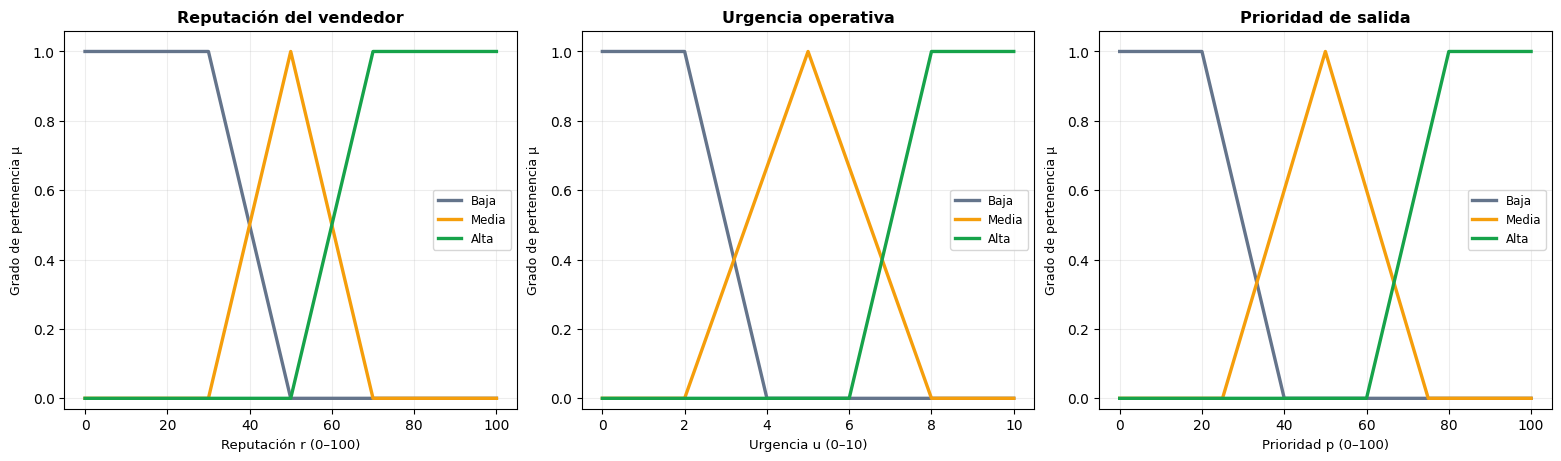

In [ ]:
# Funciones de pertenencia: generadas directamente a partir de los parámetros del modelo.
colores = {"baja": "#64748b", "media": "#f59e0b", "alta": "#16a34a"}
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.5), constrained_layout=True, facecolor="white")
for ax, universe, sets_, title, xlabel in [
    (axes[0], reputacion_u, reputacion, "Reputación del vendedor", "Reputación r (0–100)"),
    (axes[1], urgencia_u, urgencia, "Urgencia operativa", "Urgencia u (0–10)"),
    (axes[2], prioridad_u, prioridad, "Prioridad de salida", "Prioridad p (0–100)"),
]:
    for label, curve in sets_.items():
        ax.plot(universe, curve, label=label.capitalize(), color=colores[label], lw=2.4)
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=9.5)
    ax.set_ylabel("Grado de pertenencia μ", fontsize=9, labelpad=7)
    ax.set_ylim(-0.03, 1.06)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(alpha=0.22)
    ax.legend(frameon=True, fontsize=8.5, loc="best")
plt.show()

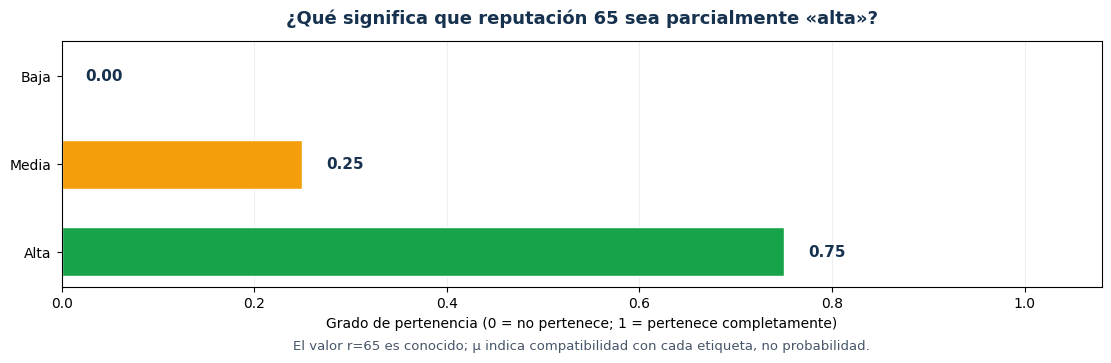

In [ ]:
# Grados de pertenencia de la reputación r=65, calculados a partir de las curvas reales.
r_ejemplo = 65
grados_r65 = {nombre: float(np.interp(r_ejemplo, reputacion_u, curva))
              for nombre, curva in reputacion.items()}
assert np.allclose([grados_r65["baja"], grados_r65["media"], grados_r65["alta"]], [0.0, 0.25, 0.75])

orden = ["baja", "media", "alta"]
valores = [grados_r65[k] for k in orden]
fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True, facecolor="white")
ax.set_facecolor("white")
ypos = np.arange(len(orden))
ax.barh(ypos, valores, color=[colores[k] for k in orden], height=0.56, edgecolor="white")
ax.set_yticks(ypos, [k.capitalize() for k in orden])
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_xlabel("Grado de pertenencia (0 = no pertenece; 1 = pertenece completamente)")
ax.set_title("¿Qué significa que reputación 65 sea parcialmente «alta»?",
             fontsize=13, fontweight="bold", color="#16324f", pad=12)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
for y, value in zip(ypos, valores):
    # La cifra 0.00 se coloca dentro del área de trazado; no se superpone con cajas ni etiquetas.
    xpos = value + 0.025 if value > 0 else 0.025
    ax.text(xpos, y, f"{value:.2f}", va="center", ha="left", fontsize=11,
            fontweight="bold", color="#16324f")
ax.text(0.5, -0.24,
        "El valor r=65 es conocido; μ indica compatibilidad con cada etiqueta, no probabilidad.",
        ha="center", va="center", transform=ax.transAxes, fontsize=9.5, color="#475569")
plt.show()

# 3. Reglas lingüísticas

Cada regla expresa una decisión de la política logística. El operador **Y (AND)** se calculará con el mínimo de los grados de pertenencia.

Ejemplo:

> SI reputación es alta Y urgencia es media, ENTONCES prioridad es alta.

El operador mínimo es una elección habitual para la conjunción en un sistema Mamdani; no es la única opción posible. La tabla de nueve reglas es una política didáctica diseñada para cubrir todas las combinaciones de etiquetas.

In [ ]:
reglas = [
    ("baja",  "baja",  "baja"),
    ("baja",  "media", "baja"),
    ("baja",  "alta",  "media"),
    ("media", "baja",  "baja"),
    ("media", "media", "media"),
    ("media", "alta",  "alta"),
    ("alta",  "baja",  "media"),
    ("alta",  "media", "alta"),
    ("alta",  "alta",  "alta"),
]
display(pd.DataFrame(reglas, columns=["Reputación", "Urgencia", "Prioridad"]))


,Reputación,Urgencia,Prioridad
0,baja,baja,baja
1,baja,media,baja
2,baja,alta,media
3,media,baja,baja
4,media,media,media
5,media,alta,alta
6,alta,baja,media
7,alta,media,alta
8,alta,alta,alta


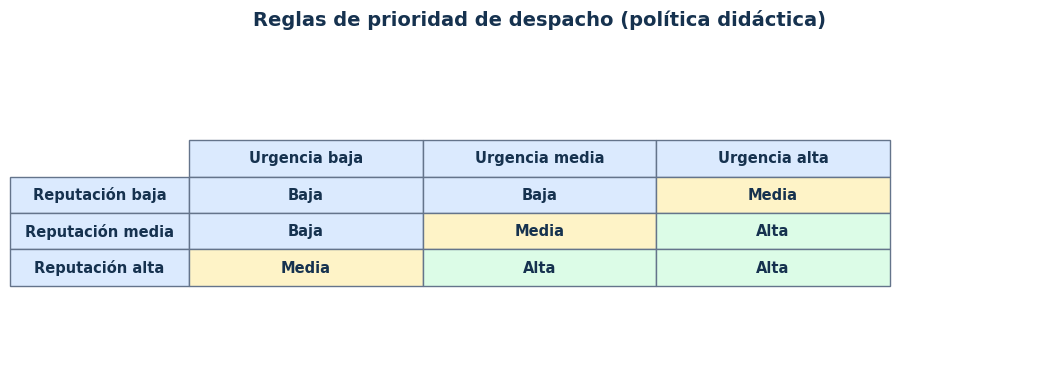

In [ ]:
# Matriz de reglas dibujada a partir de la lista `reglas` definida en la celda anterior.
import matplotlib.colors as mcolors

etiquetas = ["baja", "media", "alta"]
por_salida = {"baja": "#dbeafe", "media": "#fef3c7", "alta": "#dcfce7"}
mapa = {(r, u): s for r, u, s in reglas}
filas = [[mapa[(rep, urg)] for urg in etiquetas] for rep in etiquetas]
fig, ax = plt.subplots(figsize=(10.5, 3.8), constrained_layout=True, facecolor="white")
ax.axis("off")
ax.set_title("Reglas de prioridad de despacho (política didáctica)",
             fontsize=14, fontweight="bold", color="#16324f", pad=14)
tab = ax.table(cellText=[[x.capitalize() for x in fila] for fila in filas],
               rowLabels=[f"Reputación {x}" for x in etiquetas],
               colLabels=[f"Urgencia {x}" for x in etiquetas],
               cellLoc="center", rowLoc="center", loc="center",
               colWidths=[0.20, 0.20, 0.20])
tab.auto_set_font_size(False)
tab.set_fontsize(10.5)
tab.scale(1.15, 1.9)
for (row, col), cell in tab.get_celld().items():
    cell.set_edgecolor("#64748b")
    cell.set_linewidth(1.0)
    if row == 0 or col == -1:
        cell.set_facecolor("#dbeafe")
        cell.set_text_props(weight="bold", color="#16324f")
    else:
        out = filas[row - 1][col]
        cell.set_facecolor(por_salida[out])
        cell.set_text_props(weight="bold", color="#16324f")
plt.show()

# 4. Inferencia Mamdani

El algoritmo realiza cuatro etapas:

1. **Fuzzificación:** calcula las pertenencias de $r$ y $u$.
2. **Evaluación de reglas:** activa cada regla con $\min(\mu_r,\mu_u)$.
3. **Agregación:** combina las salidas recortadas mediante el máximo.
4. **Defuzzificación:** calcula un único puntaje con el centroide.

$$p^*=\frac{\int p\,\mu_{\text{agregada}}(p)\,dp}{\int \mu_{\text{agregada}}(p)\,dp}$$

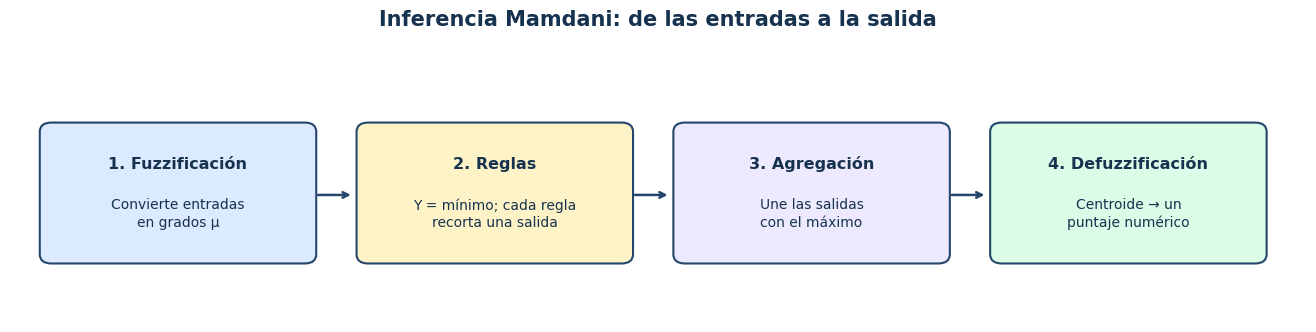

In [ ]:
# Diagrama conceptual de las cuatro etapas Mamdani.
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13.5, 3.7), facecolor="white")
ax.set_xlim(0, 13.5)
ax.set_ylim(0, 3.7)
ax.axis("off")
steps = [
    (0.35, "1. Fuzzificación", "Convierte entradas\nen grados μ" , "#dbeafe"),
    (3.65, "2. Reglas", "Y = mínimo; cada regla\nrecorta una salida", "#fef3c7"),
    (6.95, "3. Agregación", "Une las salidas\ncon el máximo", "#ede9fe"),
    (10.25, "4. Defuzzificación", "Centroide → un\npuntaje numérico", "#dcfce7"),
]
for x, title, detail, color in steps:
    patch = FancyBboxPatch((x, 0.8), 2.8, 1.75,
                           boxstyle="round,pad=0.04,rounding_size=0.12",
                           facecolor=color, edgecolor="#24466b", linewidth=1.5)
    ax.add_patch(patch)
    ax.text(x + 1.4, 2.05, title, ha="center", va="center", fontsize=11.5,
            fontweight="bold", color="#16324f")
    ax.text(x + 1.4, 1.4, detail, ha="center", va="center", fontsize=10,
            color="#16324f", linespacing=1.35)
for x1, x2 in [(3.18, 3.58), (6.48, 6.88), (9.78, 10.18)]:
    ax.annotate("", xy=(x2, 1.65), xytext=(x1, 1.65),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#24466b"))
ax.set_title("Inferencia Mamdani: de las entradas a la salida", fontsize=15,
             fontweight="bold", color="#16324f", pad=8)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.05, top=0.82)
plt.show()

In [ ]:
def pertenencia_en(valor, universo, curva):
    """Interpola una pertenencia y rechaza valores fuera del universo modelado."""
    valor = float(valor)
    if not np.isfinite(valor):
        raise ValueError("La entrada debe ser un número finito.")
    if valor < universo[0] or valor > universo[-1]:
        raise ValueError(f"La entrada {valor} está fuera del rango [{universo[0]}, {universo[-1]}].")
    return float(np.interp(valor, universo, curva))


def centroide(universo, curva):
    """Defuzzificación por centroide (centro de gravedad) de la salida agregada."""
    universo = np.asarray(universo, dtype=float)
    curva = np.asarray(curva, dtype=float)
    if universo.shape != curva.shape:
        raise ValueError("El universo y la curva deben tener la misma forma.")
    if not np.all(np.isfinite(curva)):
        raise ValueError("La curva agregada contiene valores no finitos.")
    integrar = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    area = integrar(curva, universo)
    if np.isclose(area, 0.0):
        raise ValueError("No hay área en la salida agregada; no se puede calcular el centroide.")
    return float(integrar(universo * curva, universo) / area)


def inferencia_mamdani(rep, urg, devolver_detalle=False):
    """Calcula prioridad 0–100 a partir de reputación 0–100 y urgencia 0–10."""
    rep, urg = float(rep), float(urg)
    if not np.isfinite(rep) or not 0 <= rep <= 100:
        raise ValueError("La reputación debe ser un número finito entre 0 y 100.")
    if not np.isfinite(urg) or not 0 <= urg <= 10:
        raise ValueError("La urgencia debe ser un número finito entre 0 y 10.")

    grados_rep = {k: pertenencia_en(rep, reputacion_u, v) for k, v in reputacion.items()}
    grados_urg = {k: pertenencia_en(urg, urgencia_u, v) for k, v in urgencia.items()}
    agregado = np.zeros_like(prioridad_u)
    detalle = []

    for rep_etq, urg_etq, salida in reglas:
        # AND (mínimo), implicación Mamdani (recorte) y agregación (máximo).
        activacion = min(grados_rep[rep_etq], grados_urg[urg_etq])
        recorte = np.minimum(activacion, prioridad[salida])
        agregado = np.maximum(agregado, recorte)
        detalle.append({
            "reputación": rep_etq,
            "urgencia": urg_etq,
            "prioridad": salida,
            "activación": activacion,
        })

    resultado = centroide(prioridad_u, agregado)
    if devolver_detalle:
        return resultado, grados_rep, grados_urg, agregado, detalle
    return resultado


# 5. Ejecución del pedido ML-2048

Con $r=65$ y $u=7$ se activan simultáneamente etiquetas medias y altas. Por eso varias reglas contribuyen a la salida final. El puntaje es la salida del modelo didáctico definido arriba, no una decisión real de Mercado Libre.

## Del dato al puntaje: diagrama reproducible

Este esquema se construye a partir de la salida real calculada por el notebook. Los números se actualizan al cambiar las entradas o las reglas.

In [ ]:
pedido_id = "ML-2048"
r_entrada, u_entrada = 65, 7

resultado, grados_rep, grados_urg, agregado, detalle = inferencia_mamdani(
    r_entrada, u_entrada, devolver_detalle=True
)

assert np.isclose(grados_rep["media"], 0.25)
assert np.isclose(grados_rep["alta"], 0.75)
assert np.isclose(grados_urg["media"], 1/3)
assert np.isclose(grados_urg["alta"], 0.50)
assert np.isclose(resultado, 70.1672721768, atol=1e-6)
assert len(reglas) == 9  # una regla por cada combinación de etiquetas
assert all(0.0 <= grado <= 1.0 for grado in grados_rep.values())
assert all(0.0 <= grado <= 1.0 for grado in grados_urg.values())
grados_salida = {k: pertenencia_en(resultado, prioridad_u, v) for k, v in prioridad.items()}

print(f"Pedido: {pedido_id}")
print(f"Prioridad calculada: {resultado:.2f} / 100")
print("Reputación:", {k: round(v, 3) for k, v in grados_rep.items()})
print("Urgencia:", {k: round(v, 3) for k, v in grados_urg.items()})
print("Pertenencia del resultado:", {k: round(v, 3) for k, v in grados_salida.items()})

activas = pd.DataFrame(detalle)
activas = activas[activas["activación"] > 0].sort_values("activación", ascending=False)
display(activas.style.format({"activación": "{:.3f}"}))


Pedido: ML-2048
Prioridad calculada: 70.17 / 100
Reputación: {'baja': 0.0, 'media': 0.25, 'alta': 0.75}
Urgencia: {'baja': 0.0, 'media': 0.333, 'alta': 0.5}
Pertenencia del resultado: {'baja': 0.0, 'media': 0.193, 'alta': 0.508}


,reputación,urgencia,prioridad,activación
8,alta,alta,alta,0.500
7,alta,media,alta,0.333
5,media,alta,alta,0.250
4,media,media,media,0.250


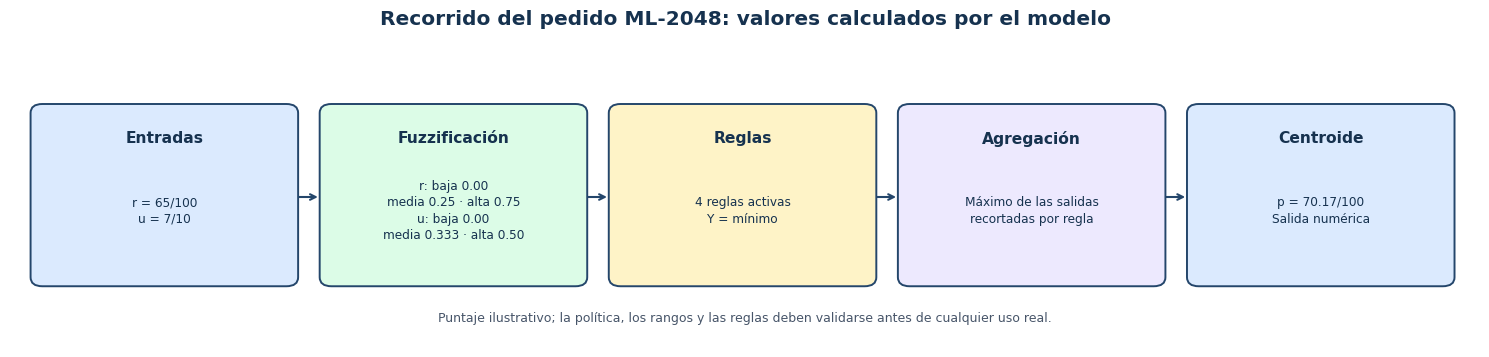

In [ ]:
# Resumen dinámico del recorrido: todos los números vienen de la inferencia ejecutada.
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 4.15), facecolor="white")
ax.set_facecolor("white")
ax.set_xlim(0, 15)
ax.set_ylim(0, 4.15)
ax.axis("off")
steps = [
    (0.25, "Entradas", f"r = {r_entrada}/100\nu = {u_entrada}/10", "#dbeafe"),
    (3.20, "Fuzzificación",
     f"r: baja {grados_rep['baja']:.2f}\nmedia {grados_rep['media']:.2f} · alta {grados_rep['alta']:.2f}\n"
     f"u: baja {grados_urg['baja']:.2f}\nmedia {grados_urg['media']:.3f} · alta {grados_urg['alta']:.2f}", "#dcfce7"),
    (6.15, "Reglas", f"{sum(d['activación'] > 0 for d in detalle)} reglas activas\nY = mínimo", "#fef3c7"),
    (9.10, "Agregación", "Máximo de las salidas\nrecortadas por regla", "#ede9fe"),
    (12.05, "Centroide", f"p = {resultado:.2f}/100\nSalida numérica", "#dbeafe"),
]
width = 2.65
for x, title, detail, color in steps:
    patch = FancyBboxPatch((x, 0.85), width, 2.35,
                           boxstyle="round,pad=0.04,rounding_size=0.12",
                           facecolor=color, edgecolor="#24466b", linewidth=1.4)
    ax.add_patch(patch)
    ax.text(x + width/2, 2.78, title, ha="center", va="center",
            fontsize=11.2, fontweight="bold", color="#16324f")
    ax.text(x + width/2, 1.82, detail, ha="center", va="center",
            fontsize=8.7, color="#16324f", linespacing=1.35)
for left_x, right_x in [(2.92, 3.17), (5.87, 6.12), (8.82, 9.07), (11.77, 12.02)]:
    ax.annotate("", xy=(right_x, 2.0), xytext=(left_x, 2.0),
                arrowprops=dict(arrowstyle="->", lw=1.5, color="#24466b"))
ax.text(7.5, 0.38,
        "Puntaje ilustrativo; la política, los rangos y las reglas deben validarse antes de cualquier uso real.",
        ha="center", va="center", fontsize=9, color="#475569")
ax.set_title("Recorrido del pedido ML-2048: valores calculados por el modelo",
             fontsize=14.5, fontweight="bold", color="#16324f", pad=8)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.05, top=0.80)
plt.show()

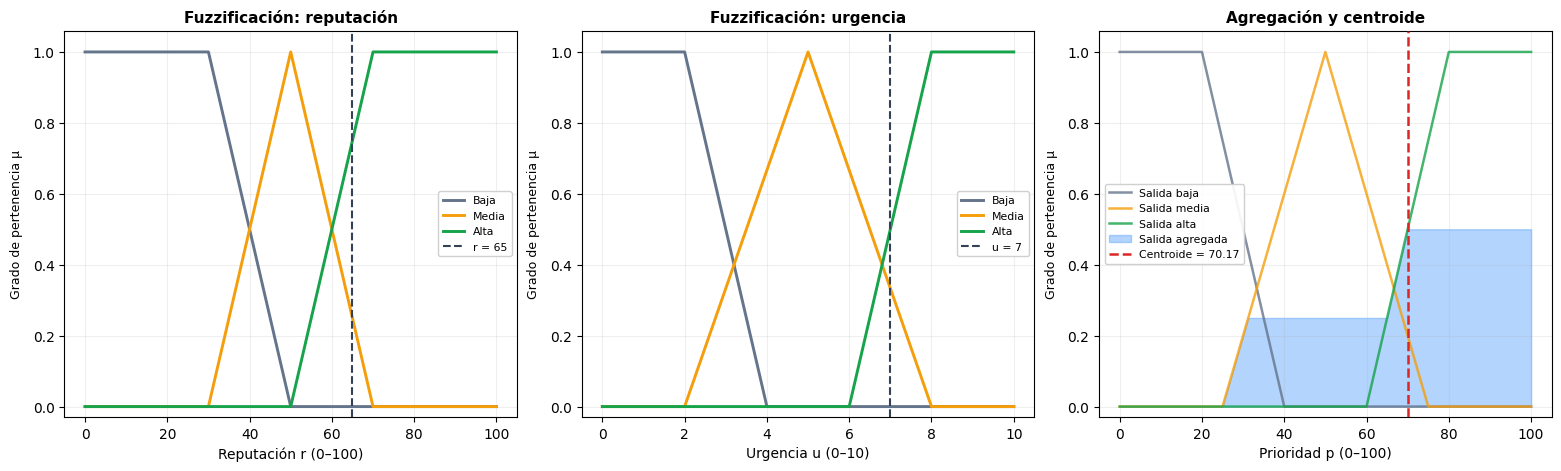

In [ ]:
# Funciones de entrada con sus valores y salida agregada con el centroide calculado.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), constrained_layout=True, facecolor="white")

for name, curve in reputacion.items():
    axes[0].plot(reputacion_u, curve, label=name.capitalize(), color=colores[name], lw=2.1)
axes[0].axvline(r_entrada, color="#334155", linestyle="--", lw=1.5,
                label=f"r = {r_entrada}")
axes[0].set_title("Fuzzificación: reputación", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Reputación r (0–100)")

for name, curve in urgencia.items():
    axes[1].plot(urgencia_u, curve, label=name.capitalize(), color=colores[name], lw=2.1)
axes[1].axvline(u_entrada, color="#334155", linestyle="--", lw=1.5,
                label=f"u = {u_entrada}")
axes[1].set_title("Fuzzificación: urgencia", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Urgencia u (0–10)")

for name, curve in prioridad.items():
    axes[2].plot(prioridad_u, curve, label=f"Salida {name}", color=colores[name], lw=1.8, alpha=0.8)
axes[2].fill_between(prioridad_u, 0, agregado, color="#60a5fa", alpha=0.48,
                     label="Salida agregada", zorder=1)
axes[2].axvline(resultado, color="#dc2626", linestyle="--", lw=1.8,
                label=f"Centroide = {resultado:.2f}", zorder=3)
axes[2].set_title("Agregación y centroide", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Prioridad p (0–100)")

for ax in axes:
    ax.set_ylim(-0.03, 1.06)
    ax.set_ylabel("Grado de pertenencia μ", fontsize=9, labelpad=7)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7.8, framealpha=0.92, loc="best")
plt.show()

## Interpretación operativa

El sistema asigna **70.17/100** al pedido ML-2048. El número no proviene de una sola regla: es el centroide de todas las salidas activadas.

En este modelo, el resultado tiene mayor pertenencia al conjunto **alta** que al conjunto **media**; eso no equivale por sí solo a una decisión empresarial definitiva. Para convertir el puntaje en una acción (por ejemplo, prioridad de despacho alta), habría que definir explícitamente el umbral operativo y medir sus consecuencias.

La prioridad es una recomendación explicable, pero su validez depende de que las funciones y reglas hayan sido calibradas. Usar reputación también puede favorecer sistemáticamente a ciertos vendedores, por lo que la política debe evaluarse con criterios de equidad, desempeño logístico y posibles variables alternativas. Recuerda que este caso es hipotético y no representa el algoritmo real de Mercado Libre.

,Pedido,Reputación,Urgencia,Prioridad
0,ML-A,20,2,15.56
1,ML-B,50,5,50.00
2,ML-C,80,9,84.44


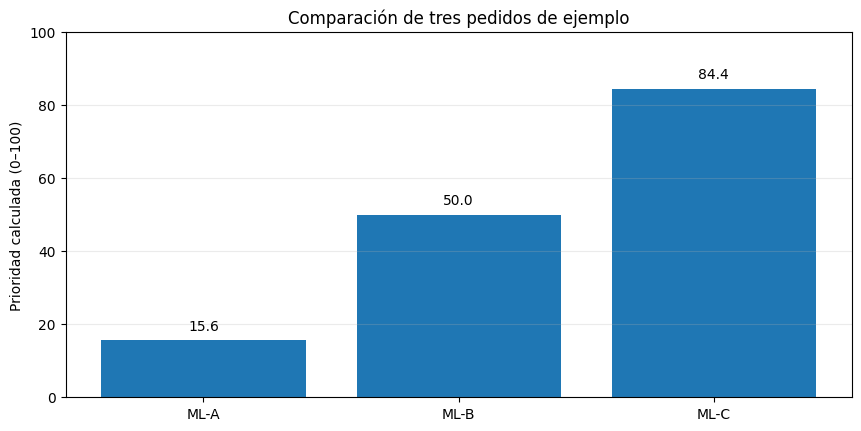

In [ ]:
# Tres pedidos para comparar la política
pedidos = pd.DataFrame([
    {"Pedido": "ML-A", "Reputación": 20, "Urgencia": 2},
    {"Pedido": "ML-B", "Reputación": 50, "Urgencia": 5},
    {"Pedido": "ML-C", "Reputación": 80, "Urgencia": 9},
])
pedidos["Prioridad"] = pedidos.apply(
    lambda fila: inferencia_mamdani(fila["Reputación"], fila["Urgencia"]), axis=1
)
display(pedidos.style.format({"Prioridad": "{:.2f}"}))


fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True, facecolor="white")
barras = ax.bar(pedidos["Pedido"], pedidos["Prioridad"])
ax.set_ylim(0, 100)
ax.set_ylabel("Prioridad calculada (0–100)")
ax.set_title("Comparación de tres pedidos de ejemplo")
ax.grid(axis="y", alpha=0.25)
for barra, valor in zip(barras, pedidos["Prioridad"]):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 2, f"{valor:.1f}", ha="center", va="bottom")
plt.show()


# Actividad breve

Para el pedido **ML-3051**, con reputación $r=60$ y urgencia $u=4$:

1. Identifica las etiquetas con pertenencia mayor que cero.
2. Señala qué reglas se activarán.
3. Ejecuta `inferencia_mamdani(60, 4)` y explica por qué la salida no coincide exactamente con baja, media o alta.

### Ideas para recordar

- $\mu$ mide pertenencia a un concepto, no probabilidad.
- Una entrada puede pertenecer a varias etiquetas al mismo tiempo.
- Mamdani combina varias reglas y entrega una salida numérica continua.
- Las reglas representan decisiones humanas y deben validarse.

**Comprobación adicional:** prueba `inferencia_mamdani(105, 4)` e `inferencia_mamdani(60, 12)`. Ambas entradas deben rechazarse porque están fuera de los rangos definidos, en vez de generar un puntaje aparentemente válido.